<a href="https://colab.research.google.com/github/2025ct05023-coder/Pritam-MLOps-Assignment1/blob/main/heart_disease_mlops.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import urllib.request
import pandas as pd

# URL to the processed Cleveland dataset on UCI ML Repository
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data'
output_file = 'heart.csv'

try:
    print(f"Downloading dataset from: {url}")
    urllib.request.urlretrieve(url, output_file)
    print(f"Successfully saved dataset as: {output_file}")

    # Verify by loading into pandas
    columns = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
    df = pd.read_csv(output_file, names=columns, na_values='?')
    print(f"Dataset shape: {df.shape}")
    display(df.head())
except Exception as e:
    print(f"An error occurred: {e}")

Successfully saved dataset as: heart.csv
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Handle missing values
print("Missing values per column:")
print(df.isnull().sum())

# Impute missing values with median for simplicity and robustness
for col in ['ca', 'thal']:
    if df[col].isnull().sum() > 0:
        median_val = df[col].median()
        df[col].fillna(median_val, inplace=True)
        print(f"Imputed missing values in column '{col}' with median: {median_val}")

# 2. Binarize target: 0 remains 0 (absence), values >= 1 become 1 (presence of heart disease)
df['target'] = df['target'].apply(lambda x: 1 if x > 0 else 0)

print("\nUpdated target value distribution:")
print(df['target'].value_counts())

# 3. Save cleaned dataset
df.to_csv('heart_cleaned.csv', index=False)
print("\nCleaned dataset saved as 'heart_cleaned.csv'")

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64
Imputed missing values in column 'ca' with median: 0.0
Imputed missing values in column 'thal' with median: 3.0

Updated target value distribution:
target
0    164
1    139
Name: count, dtype: int64

Cleaned dataset saved as 'heart_cleaned.csv'


/tmp/ipykernel_3025/3642351802.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(median_val, inplace=True)


<Figure size 1500x1200 with 0 Axes>

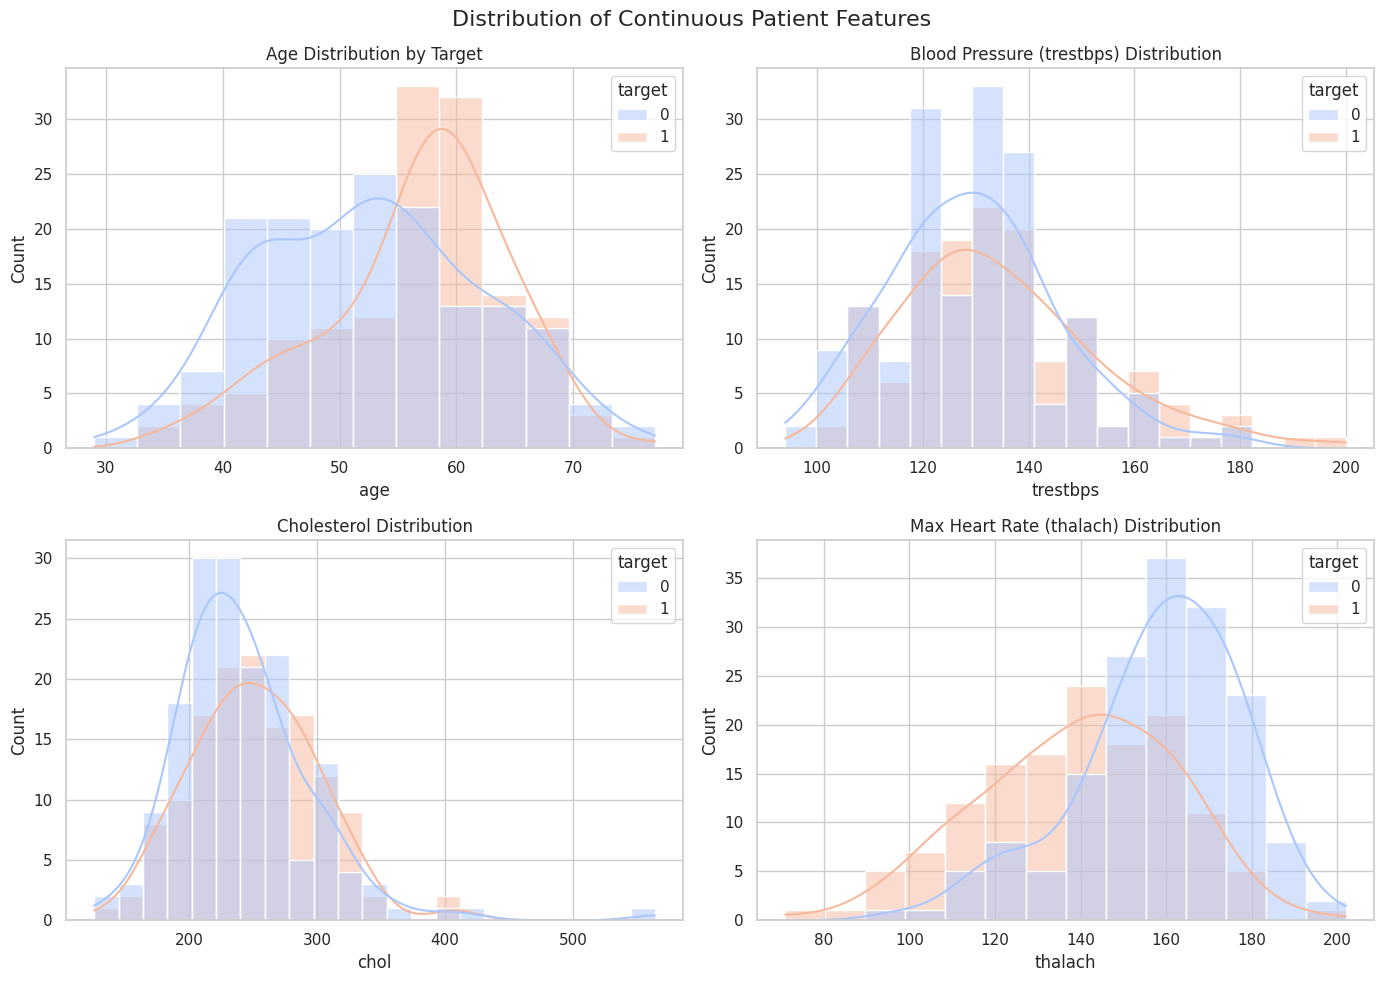

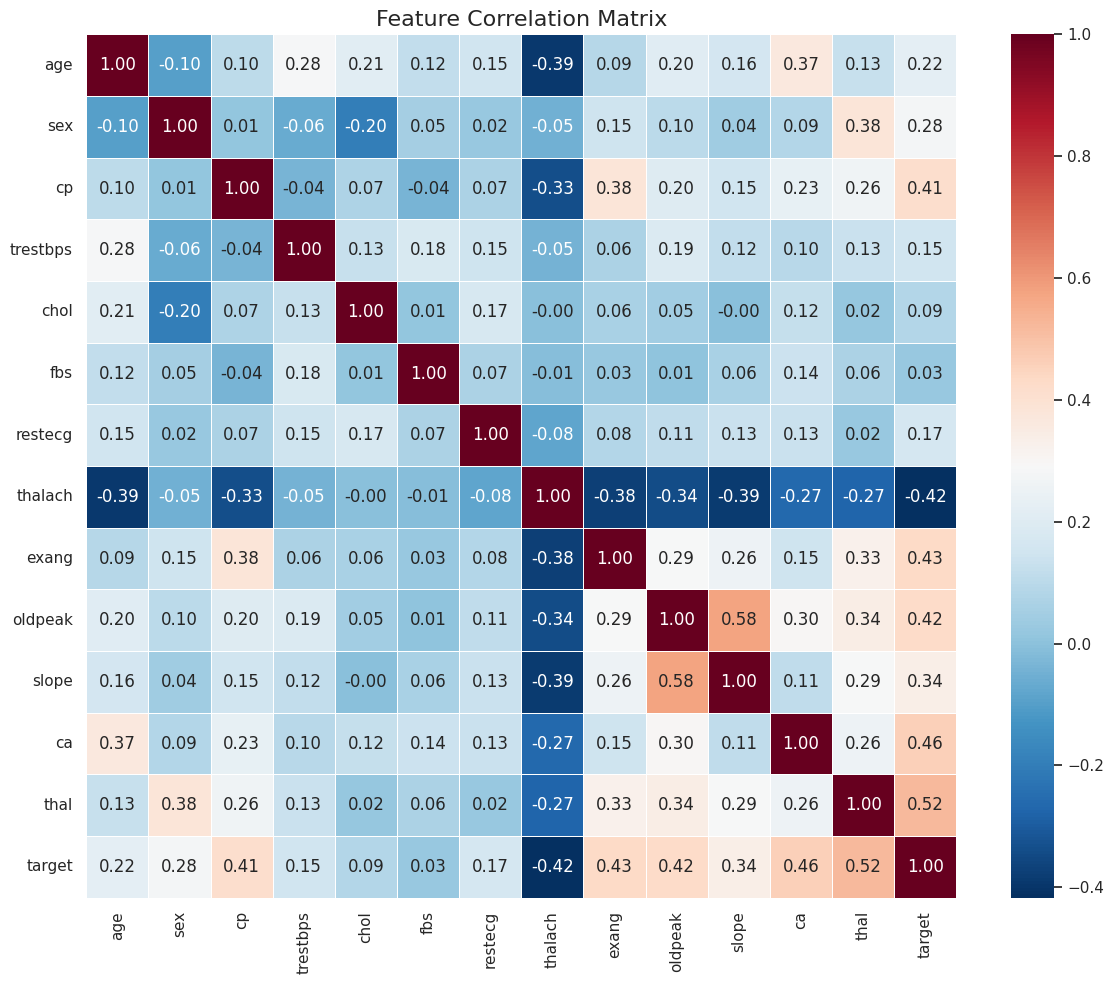

/tmp/ipykernel_3025/4044532733.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='target', palette='Set2')


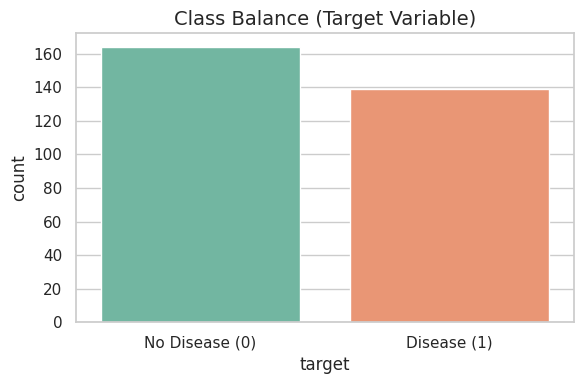

In [ ]:
# Set up plotting styles
sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 12))

# Plot 1: Histograms of Continuous Variables
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Distribution of Continuous Patient Features', fontsize=16)
sns.histplot(data=df, x='age', hue='target', kde=True, ax=axes[0,0], palette='coolwarm')
axes[0,0].set_title('Age Distribution by Target')

sns.histplot(data=df, x='trestbps', hue='target', kde=True, ax=axes[0,1], palette='coolwarm')
axes[0,1].set_title('Blood Pressure (trestbps) Distribution')

sns.histplot(data=df, x='chol', hue='target', kde=True, ax=axes[1,0], palette='coolwarm')
axes[1,0].set_title('Cholesterol Distribution')

sns.histplot(data=df, x='thalach', hue='target', kde=True, ax=axes[1,1], palette='coolwarm')
axes[1,1].set_title('Max Heart Rate (thalach) Distribution')
plt.tight_layout()
plt.savefig('eda_distributions.png')
plt.show()

# Plot 2: Correlation Heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, cmap='RdBu_r', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation Matrix', fontsize=16)
plt.tight_layout()
plt.savefig('eda_correlation_matrix.png')
plt.show()

# Plot 3: Class Balance
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='target', palette='Set2')
plt.title('Class Balance (Target Variable)', fontsize=14)
plt.xticks([0, 1], ['No Disease (0)', 'Disease (1)'])
plt.tight_layout()
plt.savefig('eda_class_balance.png')
plt.show()

In [ ]:
!pip install -q mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 604.9 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 36.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 21.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 34.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.

In [ ]:
import mlflow
import mlflow.sklearn
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import os

# Prepare features and target
X = df.drop(columns=['target'])
y = df['target']

# Split data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Define numeric and categorical columns
numeric_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
categorical_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

# Enable local MLflow logging
mlflow.set_experiment("Heart_Disease_MLOps")

def evaluate_and_log_model(model_name, model, param_dict):
    # Build final processing & model pipeline
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_features),
            ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
        ]
    )

    clf_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                                   ('classifier', model)])

    # Cross-validation
    cv_results = cross_validate(clf_pipeline, X_train, y_train, cv=5,
                                 scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'])

    # Fit on all train data
    clf_pipeline.fit(X_train, y_train)

    # Predict
    y_pred = clf_pipeline.predict(X_test)
    y_pred_proba = clf_pipeline.predict_proba(X_test)[:, 1]

    # Test metrics
    metrics = {
        'cv_mean_accuracy': cv_results['test_accuracy'].mean(),
        'cv_mean_roc_auc': cv_results['test_roc_auc'].mean(),
        'test_accuracy': accuracy_score(y_test, y_pred),
        'test_precision': precision_score(y_test, y_pred),
        'test_recall': recall_score(y_test, y_pred),
        'test_f1': f1_score(y_test, y_pred),
        'test_roc_auc': roc_auc_score(y_test, y_pred_proba)
    }

    # Log with MLflow
    with mlflow.start_run(run_name=model_name):
        # Log params
        mlflow.log_params(param_dict)
        mlflow.log_param("model_type", model_name)

        # Log metrics
        mlflow.log_metrics(metrics)

        # Log model artifact with skops_trusted_types defined
        mlflow.sklearn.log_model(
            clf_pipeline,
            artifact_path="model",
            skops_trusted_types=[
                "sklearn.compose._column_transformer._RemainderColsList",
                "sklearn.tree._tree.Tree"
            ]
        )

        # Log EDA image artifacts
        for img in ['eda_distributions.png', 'eda_correlation_matrix.png', 'eda_class_balance.png']:
            if os.path.exists(img):
                mlflow.log_artifact(img)

    print(f"\n--- {model_name} Results ---")
    for k, v in metrics.items():
        print(f"{k}: {v:.4f}")
    return clf_pipeline

# 1. Logistic Regression Model
lr_params = {'C': 1.0, 'max_iter': 1000, 'solver': 'lbfgs'}
lr_model = LogisticRegression(**lr_params)
lr_pipeline = evaluate_and_log_model("Logistic_Regression", lr_model, lr_params)

# 2. Random Forest Model
rf_params = {'n_estimators': 100, 'max_depth': 5, 'random_state': 42}
rf_model = RandomForestClassifier(**rf_params)
rf_pipeline = evaluate_and_log_model("Random_Forest", rf_model, rf_params)

2026/10/20 16:06:12 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



--- Logistic_Regression Results ---
cv_mean_accuracy: 0.8428
cv_mean_roc_auc: 0.8937
test_accuracy: 0.8852
test_precision: 0.8387
test_recall: 0.9286
test_f1: 0.8814
test_roc_auc: 0.9665


2026/10/20 16:06:20 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



--- Random_Forest Results ---
cv_mean_accuracy: 0.8056
cv_mean_roc_auc: 0.9029
test_accuracy: 0.8689
test_precision: 0.8333
test_recall: 0.8929
test_f1: 0.8621
test_roc_auc: 0.9481


In [ ]:
import joblib

# Save our best pipeline model (lr_pipeline) locally as a PKL file for serving
model_filename = 'heart_disease_pipeline.pkl'
joblib.dump(lr_pipeline, model_filename)
print(f"Champion pipeline model successfully saved to: {model_filename}")

Champion pipeline model successfully saved to: heart_disease_pipeline.pkl


In [ ]:
# Let's write the FastAPI application script to a local python file
fastapi_code = """from fastapi import FastAPI
from pydantic import BaseModel, Field
import joblib
import pandas as pd
import numpy as np

app = FastAPI(title="Heart Disease Prediction API", description="An API to predict the risk of heart disease", version="1.0")

# Load the pre-trained champion pipeline (Preprocessor + Logistic Regression)
model = joblib.load('heart_disease_pipeline.pkl')

# Define the schema representing the 13 input features
class PatientData(BaseModel):
    age: float = Field(..., example=63.0)
    sex: float = Field(..., example=1.0) # 1 = male, 0 = female
    cp: float = Field(..., example=1.0) # chest pain type (1, 2, 3, 4)
    trestbps: float = Field(..., example=145.0) # resting blood pressure
    chol: float = Field(..., example=233.0) # serum cholesterol in mg/dl
    fbs: float = Field(..., example=1.0) # fasting blood sugar > 120 mg/dl
    restecg: float = Field(..., example=2.0) # resting electrocardiographic results (0, 1, 2)
    thalach: float = Field(..., example=150.0) # maximum heart rate achieved
    exang: float = Field(..., example=0.0) # exercise induced angina
    oldpeak: float = Field(..., example=2.3) # ST depression induced by exercise
    slope: float = Field(..., example=3.0) # the slope of the peak exercise ST segment
    ca: float = Field(..., example=0.0) # number of major vessels colored by flourosopy
    thal: float = Field(..., example=6.0) # 3 = normal; 6 = fixed defect; 7 = reversable defect

@app.get("/")
def read_root():
    return {"message": "API is online. Access documentation at /docs or send POST requests to /predict"}

@app.post("/predict")
def predict(patient: PatientData):
    # Convert Pydantic BaseModel input to a Pandas DataFrame representing a single instance
    input_dict = patient.dict()
    input_df = pd.DataFrame([input_dict])

    # Run prediction and fetch prediction confidences
    prediction = int(model.predict(input_df)[0])
    confidence = float(model.predict_proba(input_df)[0][prediction])

    return {
        "prediction": prediction,
        "confidence": confidence,
        "status": "High Risk" if prediction == 1 else "Normal / Low Risk"
    }
"""

with open('app.py', 'w') as f:
    f.write(fastapi_code)
print("FastAPI script successfully written as 'app.py'")

FastAPI script successfully written as 'app.py'


In [ ]:
!pip install -q pytest httpx

In [ ]:
import os

# Create a 'test' directory as required in the Deliverables section of the PDF
os.makedirs('test', exist_ok=True)

test_code = """import pytest
import joblib
import pandas as pd
import numpy as np
from fastapi.testclient import TestClient
from app import app

client = TestClient(app)

# 1. Test that the saved pipeline loads and can perform prediction
def test_model_loading_and_inference():
    model = joblib.load('heart_disease_pipeline.pkl')
    assert model is not None

    # Mock patient data
    sample_data = pd.DataFrame([{
        "age": 50.0, "sex": 1.0, "cp": 2.0, "trestbps": 130.0,
        "chol": 250.0, "fbs": 0.0, "restecg": 1.0, "thalach": 160.0,
        "exang": 0.0, "oldpeak": 1.2, "slope": 2.0, "ca": 0.0, "thal": 3.0
    }])

    prediction = model.predict(sample_data)
    probabilities = model.predict_proba(sample_data)

    assert len(prediction) == 1
    assert prediction[0] in [0, 1]
    assert probabilities.shape == (1, 2)

# 2. Test FastAPI Endpoints
def test_api_root():
    response = client.get("/")
    assert response.status_code == 200
    assert "API is online" in response.json()["message"]

def test_api_predict():
    payload = {
        "age": 63.0,
        "sex": 1.0,
        "cp": 1.0,
        "trestbps": 145.0,
        "chol": 233.0,
        "fbs": 1.0,
        "restecg": 2.0,
        "thalach": 150.0,
        "exang": 0.0,
        "oldpeak": 2.3,
        "slope": 3.0,
        "ca": 0.0,
        "thal": 6.0
    }
    response = client.post("/predict", json=payload)
    assert response.status_code == 200
    data = response.json()
    assert "prediction" in data
    assert "confidence" in data
    assert "status" in data
    assert data["prediction"] in [0, 1]
"""

with open('test/test_pipeline.py', 'w') as f:
    f.write(test_code)
print("Unit tests successfully written to 'test/test_pipeline.py'")

Unit tests successfully written to 'test/test_pipeline.py'


In [ ]:
# Execute pytest with current path included so that our app module is found!
!PYTHONPATH=. pytest test/

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0
rootdir: /content
plugins: typeguard-4.6.0, anyio-4.15.1, langsmith-0.14.11, platformdirs-4.13.4
collected 3 items                                                              

test/test_pipeline.py ...                                                [100%]

============================== 3 passed in 3.07s ===============================


In [ ]:
dockerfile_content = """# Use an official lightweight Python base image
FROM python:3.11-slim

# Set environment variables
ENV PYTHONDONTWRITEBYTECODE=1
ENV PYTHONUNBUFFERED=1
ENV WORKDIR=/workspace

# Set the working directory inside the container
WORKDIR ${WORKDIR}

# Install system dependencies
RUN apt-get update && apt-get install -y --no-install-recommends \
    build-essential \
    && rm -rf /var/lib/apt/lists/*

# Copy only the requirements first to utilize Docker layer caching
COPY requirements.txt .

# Install application dependencies
RUN pip install --no-cache-dir -r requirements.txt

# Copy the application source code and pre-trained model artifact
COPY app.py .
COPY heart_disease_pipeline.pkl .

# Expose port 8000 for FastAPI service
EXPOSE 8000

# Start the FastAPI application via uvicorn server
CMD [\"uvicorn\", \"app:app\", \"--host\", \"0.0.0.0\", \"--port\", \"8000\"]
"""

requirements_content = """fastapi>=0.100.0
uvicorn>=0.22.0
pydantic>=2.0
joblib>=1.2.0
pandas>=2.0.0
numpy>=1.24.0
scikit-learn>=1.2.0
skops>=0.9.0
"""

with open('Dockerfile', 'w') as f:
    f.write(dockerfile_content)
print("Dockerfile successfully written.")

with open('requirements.txt', 'w') as f:
    f.write(requirements_content)
print("requirements.txt successfully written.")

Dockerfile successfully written.
requirements.txt successfully written.


In [ ]:
import os

# Create directory structures for CI/CD workflow and Kubernetes manifests
os.makedirs('.github/workflows', exist_ok=True)
os.makedirs('k8s', exist_ok=True)

# 1. Write the GitHub Actions Workflow YAML file (Task 5)
github_workflow = """name: MLOps End-to-End CI/CD Pipeline

on:
  push:
    branches: [ main ]
  pull_request:
    branches: [ main ]

jobs:
  build-and-test:
    runs-on: ubuntu-latest

    steps:
    - name: Checkout Repository
      uses: actions/checkout@v3

    - name: Set up Python 3.10
      uses: actions/setup-python@v4
      with:
        python-version: '3.10'

    - name: Install dependencies
      run: |
        python -m pip install --upgrade pip
        pip install -r requirements.txt
        pip install pytest httpx

    - name: Code Quality Linting
      run: |
        pip install flake8
        # stop the build if there are Python syntax errors or undefined names
        flake8 . --count --select=E9,F63,F7,F82 --show-source --statistics

    - name: Run Unit Tests
      run: |
        PYTHONPATH=. pytest test/
"""

# 2. Write the Kubernetes Deployment & Service Manifest (Task 7)
k8s_deployment = """apiVersion: apps/v1
kind: Deployment
metadata:
  name: heart-disease-api
  labels:
    app: heart-disease-api
spec:
  replicas: 2
  selector:
    matchLabels:
      app: heart-disease-api
  template:
    metadata:
      labels:
        app: heart-disease-api
    spec:
      containers:
      - name: api-container
        image: heart-disease-api:latest
        imagePullPolicy: IfNotPresent
        ports:
        - containerPort: 8000
        resources:
          limits:
            cpu: "500m"
            memory: "512Mi"
          requests:
            cpu: "250m"
            memory: "256Mi"
---
apiVersion: v1
kind: Service
metadata:
  name: heart-disease-api-service
spec:
  type: LoadBalancer
  ports:
  - port: 80
    targetPort: 8000
    protocol: TCP
  selector:
    app: heart-disease-api
"""

with open('.github/workflows/mlops-pipeline.yml', 'w') as f:
    f.write(github_workflow)
print("GitHub Actions Workflow successfully written to '.github/workflows/mlops-pipeline.yml'")

with open('k8s/deployment.yaml', 'w') as f:
    f.write(k8s_deployment)
print("Kubernetes deployment manifests successfully written to 'k8s/deployment.yaml'")

GitHub Actions Workflow successfully written to '.github/workflows/mlops-pipeline.yml'
Kubernetes deployment manifests successfully written to 'k8s/deployment.yaml'


In [ ]:
import os

# Create directory structures for CI/CD workflow and Kubernetes manifests
os.makedirs('.github/workflows', exist_ok=True)
os.makedirs('k8s', exist_ok=True)

# 1. Write the GitHub Actions Workflow YAML file (Task 5)
github_workflow = """name: MLOps End-to-End CI/CD Pipeline

on:
  push:
    branches: [ main ]
  pull_request:
    branches: [ main ]

jobs:
  build-and-test:
    runs-on: ubuntu-latest

    steps:
    - name: Checkout Repository
      uses: actions/checkout@v3

    - name: Set up Python 3.10
      uses: actions/setup-python@v4
      with:
        python-version: '3.10'

    - name: Install dependencies
      run: |
        python -m pip install --upgrade pip
        pip install -r requirements.txt
        pip install pytest httpx

    - name: Code Quality Linting
      run: |
        pip install flake8
        # stop the build if there are Python syntax errors or undefined names
        flake8 . --count --select=E9,F63,F7,F82 --show-source --statistics

    - name: Run Unit Tests
      run: |
        PYTHONPATH=. pytest test/
"""

# 2. Write the Kubernetes Deployment & Service Manifest (Task 7)
k8s_deployment = """apiVersion: apps/v1
kind: Deployment
metadata:
  name: heart-disease-api
  labels:
    app: heart-disease-api
spec:
  replicas: 2
  selector:
    matchLabels:
      app: heart-disease-api
  template:
    metadata:
      labels:
        app: heart-disease-api
    spec:
      containers:
      - name: api-container
        image: heart-disease-api:latest
        imagePullPolicy: IfNotPresent
        ports:
        - containerPort: 8000
        resources:
          limits:
            cpu: "500m"
            memory: "512Mi"
          requests:
            cpu: "250m"
            memory: "256Mi"
---
apiVersion: v1
kind: Service
metadata:
  name: heart-disease-api-service
spec:
  type: LoadBalancer
  ports:
  - port: 80
    targetPort: 8000
    protocol: TCP
  selector:
    app: heart-disease-api
"""

with open('.github/workflows/mlops-pipeline.yml', 'w') as f:
    f.write(github_workflow)
print("GitHub Actions Workflow successfully written to '.github/workflows/mlops-pipeline.yml'")

with open('k8s/deployment.yaml', 'w') as f:
    f.write(k8s_deployment)
print("Kubernetes deployment manifests successfully written to 'k8s/deployment.yaml'")

GitHub Actions Workflow successfully written to '.github/workflows/mlops-pipeline.yml'
Kubernetes deployment manifests successfully written to 'k8s/deployment.yaml'


In [ ]:
prometheus_content = """global:
  scrape_interval: 15s
  evaluation_interval: 15s

scrape_configs:
  - job_name: 'heart-disease-api'
    metrics_path: '/metrics'
    static_configs:
      - targets: ['heart-disease-api-service:80']
"""

with open('prometheus.yml', 'w') as f:
    f.write(prometheus_content)
print("Prometheus configuration successfully written to 'prometheus.yml'")

Prometheus configuration successfully written to 'prometheus.yml'
